# ¿Dónde aparece el solapamiento entre cabezas, y los atributos forman grupos con sentido? — CelebA (2026-11-01)

Motivado por *Neural Networks Are Already Clean* (Cammarata, Goodfire, 2026). Resultados calculados por
`experimentation/analysis_concat_celeba.py` (`experiments/eval_multi_celeba/concat_*.json`). 5 épocas.

**Pregunta (a), la concatenación.** En cada bloque las 4 cabezas se concatenan y pasan por `W_O` antes de sumarse
al flujo residual. Si ese paso fuera lo que solapa las cabezas, la similitud entre cabezas debería **subir** al pasar
de `z_h` (salida de la cabeza, antes de concatenar) a `c_h = W_O[:, bloque h] · z_h` (lo que esa cabeza escribe).
Medidas: CKA entre cabezas antes/después de `W_O`; solapamiento entre los subespacios donde escribe cada cabeza
(0 = ortogonales, azar = 12/48 = 0.25); y la razón de varianza `Var(Σ c_h) / Σ Var(c_h)` (1 = las escrituras no se
cancelan ni se refuerzan).

**Pregunta (b), grupos.** El artículo sostiene que lo que parece mezcla arbitraria suele ser generalización
(conceptos vecinos agrupados). Aquí: si los atributos de un mismo grupo semántico (color de pelo, vello facial,
accesorios...) los codifica la misma cabeza más de lo esperado por azar. Grupos definidos a priori en el script.

**Este notebook muestra una sola semilla** (variable `SEED`, por defecto 0; se cambia con `SEED=n` en el entorno). Cada ejecución guarda sus figuras, un `summary.json` y la copia ejecutada del notebook en `results/seed<n>/`. La comparación entre semillas se hace con esos resultados guardados, no aquí.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd().resolve().parents[1]
sys.path.append(str(root))
import os
SEED = int(os.environ.get("SEED", 0))     # semilla a mostrar (este notebook muestra UNA sola semilla)
RESULTS = Path.cwd() / "results" / f"seed{SEED}"
RESULTS.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.suptitle(f"semilla {SEED}", y=1.02, fontsize=9, color="gray")
    fig.savefig(RESULTS / name, dpi=150, bbox_inches="tight")

from modules.datasets import CelebADataset
EVAL = root / "experimentation" / "experiments" / "eval_multi_celeba"
VARIANTS = {"unconstrained": "Sin penalizar", "constrained": "Penalizado", "constrained_rank": "Penalizado + rango"}
res = {k: json.loads((EVAL / f"concat_vit-5-{k}-s{SEED}-CelebA.json").read_text()) for k in VARIANTS}
r2 = {k: np.load(EVAL / f"concat_vit-5-{k}-s{SEED}-CelebA.npz")["r2"] for k in VARIANTS}
attrs = list(CelebADataset().classes)
print("semilla", SEED)
nb_, nh = 4, r2["unconstrained"].shape[0]

semilla 0


## (a) Similitud entre cabezas antes y después de `W_O`

Si `W_O` fuera la causa del solapamiento, las barras "después" serían más altas que las "antes". Ojo: solo el
bloque 4 recibe la penalización; los bloques 1–3 son una comparación de lo que pasa sin ella.

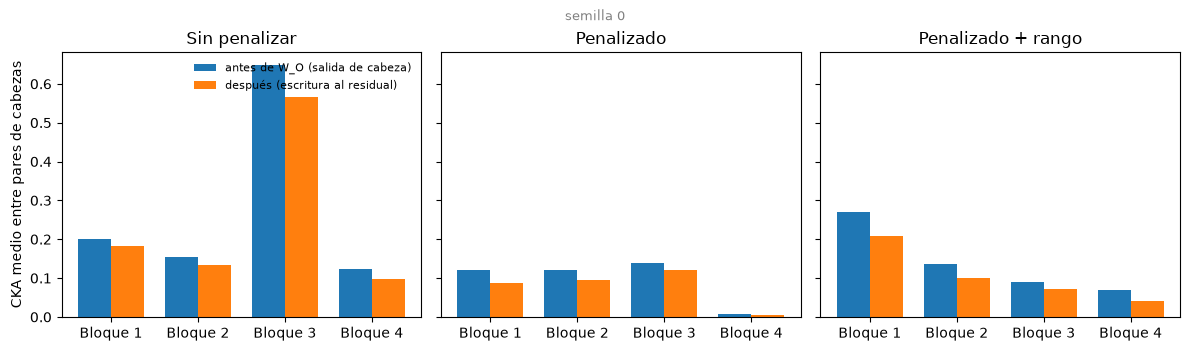

Fracción de casos (modelo x bloque) donde CKA después > antes: 0.0


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
w = 0.38
for ax, (k, name) in zip(axes, VARIANTS.items()):
    b = res[k]["blocks"]
    ax.bar(np.arange(nb_) - w/2, [x["cka_z"] for x in b], w, label="antes de W_O (salida de cabeza)")
    ax.bar(np.arange(nb_) + w/2, [x["cka_c"] for x in b], w, label="después (escritura al residual)")
    ax.set_xticks(range(nb_)); ax.set_xticklabels([f"Bloque {i+1}" for i in range(nb_)]); ax.set_title(name)
axes[0].set_ylabel("CKA medio entre pares de cabezas"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "cka_before_after_Wo.png"); plt.show()
print("Fracción de casos (modelo x bloque) donde CKA después > antes:",
      np.mean([x["cka_c"] > x["cka_z"] for k in VARIANTS for x in res[k]["blocks"]]))

## (a) ¿Escriben las cabezas en las mismas direcciones? Solapamiento de subespacios y razón de varianza

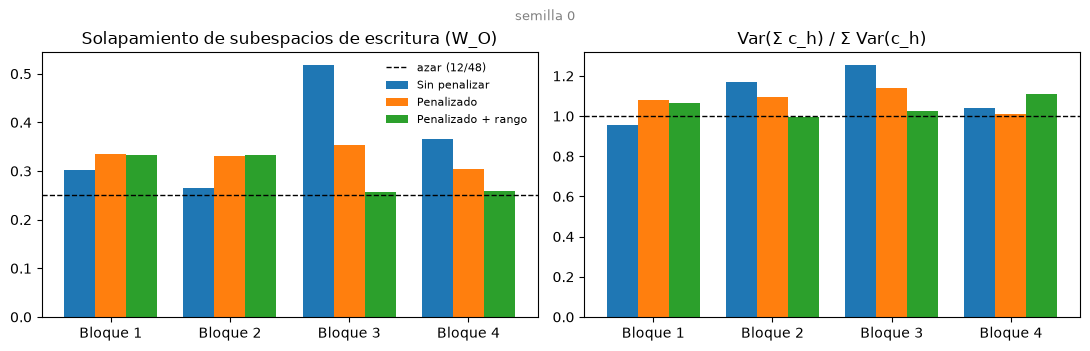

Sin penalizar        bloque 4: CKA 0.123 -> 0.097 | solapamiento 0.365 | razón varianza 1.04
Penalizado           bloque 4: CKA 0.007 -> 0.005 | solapamiento 0.305 | razón varianza 1.01
Penalizado + rango   bloque 4: CKA 0.070 -> 0.041 | solapamiento 0.259 | razón varianza 1.11


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
w = 0.26
for i, (k, name) in enumerate(VARIANTS.items()):
    axes[0].bar(np.arange(nb_) + (i-1)*w, [x["subspace_overlap"] for x in res[k]["blocks"]], w, label=name)
    axes[1].bar(np.arange(nb_) + (i-1)*w, [x["var_ratio"] for x in res[k]["blocks"]], w, label=name)
axes[0].axhline(res["unconstrained"]["chance_subspace_overlap"], color="k", ls="--", lw=1, label="azar (12/48)")
axes[1].axhline(1, color="k", ls="--", lw=1)
axes[0].set_title("Solapamiento de subespacios de escritura (W_O)"); axes[1].set_title("Var(Σ c_h) / Σ Var(c_h)")
for ax in axes: ax.set_xticks(range(nb_)); ax.set_xticklabels([f"Bloque {i+1}" for i in range(nb_)])
axes[0].legend(frameon=False, fontsize=8); plt.tight_layout(); save(fig, "subspace_overlap_var_ratio.png"); plt.show()
for k, name in VARIANTS.items():
    b = res[k]["blocks"][3]
    print(f"{name:20s} bloque 4: CKA {b['cka_z']:.3f} -> {b['cka_c']:.3f} | solapamiento {b['subspace_overlap']:.3f} | razón varianza {b['var_ratio']:.2f}")

## (b) ¿Qué cabeza codifica cada atributo? (R² del probing lineal, bloque 4)

Columnas ordenadas por grupo semántico. Si los grupos se pintan con la misma cabeza, hay agrupación con sentido.

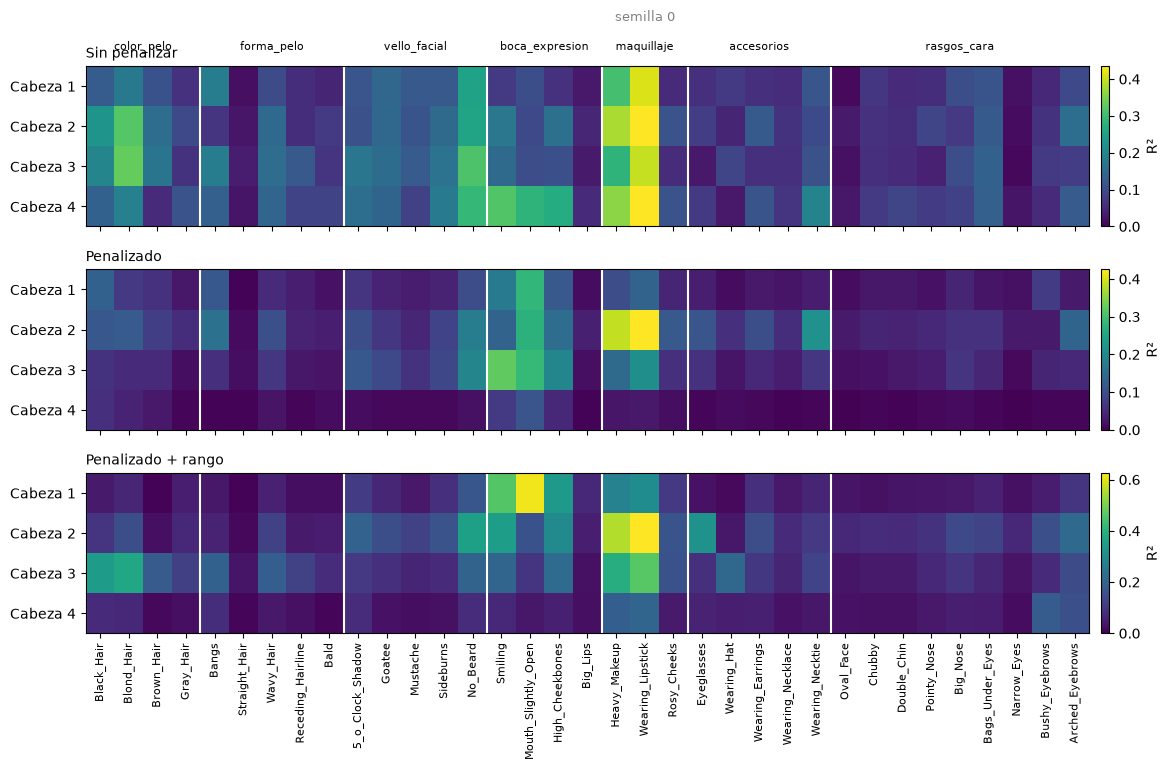

In [4]:
groups = {}
exec(open(root / "experimentation" / "analysis_concat_celeba.py").read().split("GROUPS = ")[1].split("\n}\n")[0].join(["groups = ", "\n}"]))
order, bounds, k0 = [], [], 0
for g, members in groups.items():
    order += [attrs.index(a) for a in members]; bounds.append((k0, k0 + len(members), g)); k0 += len(members)

fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
for ax, (k, name) in zip(axes, VARIANTS.items()):
    im = ax.imshow(r2[k][:, order], aspect="auto", cmap="viridis", vmin=0)
    ax.set_yticks(range(nh)); ax.set_yticklabels([f"Cabeza {h+1}" for h in range(nh)]); ax.set_title(name, loc="left", fontsize=10)
    for s, e, g in bounds: ax.axvline(s - .5, color="w", lw=1.5)
    plt.colorbar(im, ax=ax, pad=0.01, label="R²")
axes[-1].set_xticks(range(len(order))); axes[-1].set_xticklabels([attrs[i] for i in order], rotation=90, fontsize=8)
for s, e, g in bounds: axes[0].text((s + e - 1) / 2, -0.9, g, ha="center", fontsize=8)
plt.tight_layout(); save(fig, "head_attribute_r2.png"); plt.show()

### Prueba de agrupación contra azar

`same_argmax`: fracción de pares de atributos del mismo grupo cuya cabeza preferida coincide. El nulo permuta qué
atributos pertenecen a qué grupo (5000 veces), así que ya descuenta que una cabeza domine en general.

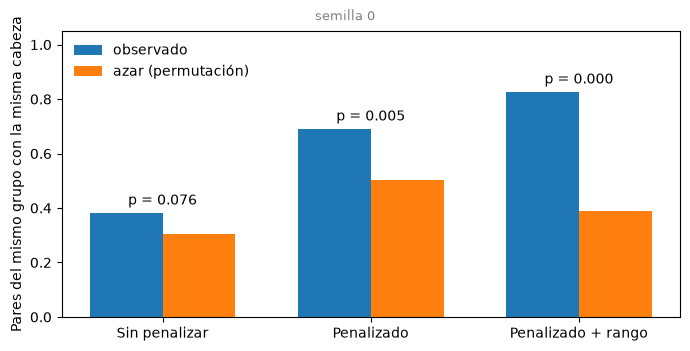


Sin penalizar
  color_pelo      cabeza preferida por atributo: [0, 1, 2, 1]
  forma_pelo      cabeza preferida por atributo: [0, 0, 4, 1]
  vello_facial    cabeza preferida por atributo: [0, 0, 4, 1]
  boca_expresion  cabeza preferida por atributo: [0, 0, 0, 4]
  maquillaje      cabeza preferida por atributo: [0, 3, 0, 0]
  accesorios      cabeza preferida por atributo: [0, 2, 1, 2]
  rasgos_cara     cabeza preferida por atributo: [1, 3, 2, 3]

Penalizado
  color_pelo      cabeza preferida por atributo: [1, 3, 0, 0]
  forma_pelo      cabeza preferida por atributo: [0, 4, 1, 0]
  vello_facial    cabeza preferida por atributo: [0, 0, 5, 0]
  boca_expresion  cabeza preferida por atributo: [0, 1, 3, 0]
  maquillaje      cabeza preferida por atributo: [0, 3, 0, 0]
  accesorios      cabeza preferida por atributo: [0, 5, 0, 0]
  rasgos_cara     cabeza preferida por atributo: [1, 7, 1, 0]

Penalizado + rango
  color_pelo      cabeza preferida por atributo: [0, 0, 4, 0]
  forma_pelo      cabez

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4)); w = 0.35
obs = [res[k]["probe"]["same_argmax"] for k in VARIANTS]; nul = [res[k]["probe"]["same_argmax_null_mean"] for k in VARIANTS]
ax.bar(np.arange(3) - w/2, obs, w, label="observado"); ax.bar(np.arange(3) + w/2, nul, w, label="azar (permutación)")
for i, k in enumerate(VARIANTS): ax.text(i, max(obs[i], nul[i]) + 0.03, f"p = {res[k]['probe']['same_argmax_p']:.3f}", ha="center")
ax.set_xticks(range(3)); ax.set_xticklabels(VARIANTS.values()); ax.set_ylim(0, 1.05); ax.legend(frameon=False)
ax.set_ylabel("Pares del mismo grupo con la misma cabeza"); plt.tight_layout(); save(fig, "group_test.png"); plt.show()
for k, name in VARIANTS.items():
    print(f"\n{name}")
    for g, v in res[k]["probe"]["per_group"].items(): print(f"  {g:15s} cabeza preferida por atributo: {v['head_counts']}")

summary = {"seed": SEED, "chance_subspace_overlap": res["unconstrained"]["chance_subspace_overlap"], "variants": {k: {
    "blocks": res[k]["blocks"],
    "cka_after_le_before_all_blocks": all(b["cka_c"] <= b["cka_z"] for b in res[k]["blocks"]),
    "group_same_argmax": res[k]["probe"]["same_argmax"], "group_null_mean": res[k]["probe"]["same_argmax_null_mean"],
    "group_p": res[k]["probe"]["same_argmax_p"], "group_head_counts": {g: v["head_counts"] for g, v in res[k]["probe"]["per_group"].items()},
} for k in VARIANTS}}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=1))
print("guardado en", RESULTS)

## Lectura

- **(a)** Si `W_O` (la concatenación) aumentara el solapamiento, las barras "después" serían más altas que las "antes"
  en la primera figura. El solapamiento de subespacios se compara contra el azar (12/48 = 0.25); la razón de varianza
  cerca de 1 indica que las escrituras de las cabezas ni se cancelan ni se refuerzan mucho.
- **(b)** La prueba de agrupación compara los pares de atributos del mismo grupo que prefieren la misma cabeza contra
  una permutación de los grupos. Un valor observado por encima del azar (p pequeño) indica que los atributos de un
  grupo tienden a ir a la misma cabeza; **no** indica que la penalización lo cause (el baseline también se evalúa).
- **Cautelas.** Esto es una sola corrida de entrenamiento; la cabeza que se lleva cada grupo cambia de una semilla a
  otra y los atributos de un mismo grupo están correlacionados en los datos. El R² del probing es bajo, por lo que la
  cabeza preferida de cada atributo es ruidosa. Con la semilla 0, por ejemplo, la agrupación del modelo
  `constrained_rank` parecía especial y en las otras semillas el baseline también agrupa. Para conclusiones comparar
  los `summary.json` de `results/seed*/`.
